# External DNA language models, with the models added in revision (Supp. Fig. 7, Fig. 4d)

Reads tables from `../data/` and writes figures to `../output/`.
Source analysis: `../../NOTEBOOK_PROVENANCE.tsv`.

The reviewer asked for a comparison against 2026 DNA foundation models. These
are the two manuscript panels that compare LEAF-1 with external DNA LMs, redrawn
in their published format with the best configuration of each added family:
CrossDNA 519M (fragment padded with N to the next multiple of 128 bp) and
AlphaGenome (fragment only, N-padded 2,048-bp input, 1-bp embedding). NTv3 is
left out of the cfDNA panels by request. Every model is scored under the published
protocol: the same 14 tasks, the same 10K fragments per sample, a mean-pooled
embedding and matched LOO nested CV with a linear SVM.

The five original baselines and LEAF-1 reproduce the published numbers exactly.
The k-mer rows of panel a are copied unchanged from the published table.

Panels:
- `cfdna_kmer_lm_delta_auc` (Supp. Fig. 7, layout of 2026-10-19):
  a, mean AUC (BCa 95% CI, 10,000 resamples) of LEAF-1 and the external DNA LMs,
  with per-task AUC overlaid, LEAF-1 first and the others in panel b order;
  b, mean ΔAUC (LEAF-1 − baseline) with paired BCa 95% CI against the external
  DNA LMs, including all three CrossDNA sizes (8M, 72M, 519M; same padding rule);
  c, the same against the k-mer baselines (panel a in the submission). A ΔAUC bar
  is blue when its CI excludes 0 and orange otherwise. b and c share one bar pitch.
- `cfdna_external_lm_auc_table.tsv`: the numbers behind a and b (mean AUC and
  ΔAUC with 95% CIs, per-task wins/losses), so every value quoted in the
  response letter appears in the supplement.

The external rows of `../data/cfdna_delta_auc_*.csv` are at full precision
(2026-10-19). The earlier 4-decimal tables double-rounded values near a
boundary, e.g. CrossDNA 519M mean AUC 0.85047 printed as 0.851 and ΔAUC
0.00451 printed as 0.004.
- `cfdna_external_lm_model_size`: mean AUC (BCa 95%, 9,999 resamples) against
  parameter count, with a broken x-axis for Evo 2.


In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from notebook/, from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA.relative_to(_p))
print("OUT :", OUT.relative_to(_p))

DATA: cfdna/data
OUT : cfdna/output


In [2]:
# ── Data ──────────────────────────────────────────────────────────────────────
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.transforms as mtrans
from matplotlib.lines import Line2D
from scipy import stats as sp_stats

# round_trip: pandas' default float parser is not correctly rounded.
summary = pd.read_csv(DATA / "cfdna_delta_auc_summary.csv", float_precision="round_trip")
per_task = pd.read_csv(DATA / "cfdna_delta_auc_per_task.csv", float_precision="round_trip")
params = pd.read_csv(DATA / "cfdna_dnalm_parameter_counts.csv")

# Per-task AUC for Fig. 4d, rebuilt from the external rows of the per-task table.
ext = per_task[per_task["comparison"] == "external"]
auc = ext.pivot(index="task", columns="baseline", values="baseline_auc")
leaf = ext.groupby("task")["leaf1_auc"]
assert (leaf.nunique() == 1).all(), "LEAF-1 AUC differs between baselines"
auc.insert(0, "LEAF-1", leaf.first())
MODELS = params["model"].tolist()
DISPLAY = params.set_index("model")["display"].to_dict()
PARAMS = params.set_index("model")["params"].to_dict()
print(summary.round(4).to_string(index=False))


comparison             baseline baseline_display  mean_delta  mean_delta_lo  mean_delta_hi  n  wins  losses
  external              gena-lm          GENA-LM      0.0428         0.0244         0.0657 14    13       1
  external             dnabert2        DNABERT-2      0.0320         0.0067         0.0648 14     9       5
  external            dnabert-s        DNABERT-S      0.0420         0.0122         0.1157 14     9       5
  external                nt-v2            NT-v2      0.0285         0.0139         0.0645 14    10       3
  external                 evo2            Evo 2      0.0440         0.0077         0.0842 14    11       3
  external  crossdna-519M-pm128    CrossDNA 519M      0.0045        -0.0218         0.0262 14     8       6
  external alphagenome-npad-1bp      AlphaGenome      0.0204        -0.0083         0.0652 14     5       9
  external  crossdna-8.1M-pm128      CrossDNA 8M      0.0388         0.0081         0.0815 14     9       5
  external crossdna-71.6M-pm

saved: cfdna/output/cfdna_kmer_lm_delta_auc.pdf
saved: cfdna/output/cfdna_kmer_lm_delta_auc.png
saved: cfdna/output/cfdna_kmer_lm_delta_auc.svg
saved: cfdna/output/cfdna_kmer_lm_delta_auc.tsv


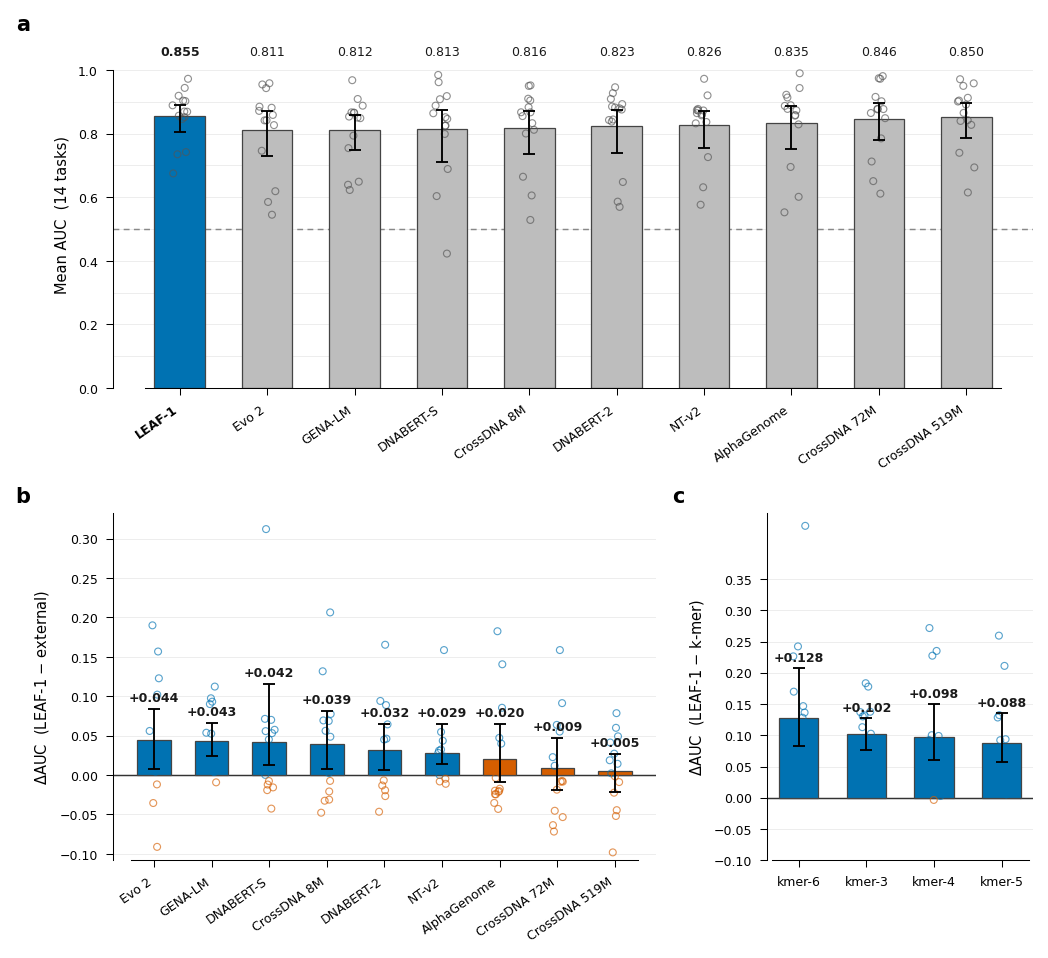

        model  parameters_M mean_auc  mean_auc_ci95 delta_auc_leaf1_minus_model  delta_auc_ci95 tasks_leaf1_higher tasks_model_higher
       LEAF-1          90.4    0.855 0.804 to 0.890                                                                                  
CrossDNA 519M         519.0    0.850 0.787 to 0.895                       0.005 -0.022 to 0.026                  8                  6
 CrossDNA 72M          71.6    0.846 0.778 to 0.897                       0.009 -0.019 to 0.047                  6                  8
  AlphaGenome         450.5    0.835 0.752 to 0.887                       0.020 -0.008 to 0.065                  5                  9
        NT-v2         500.0    0.826 0.755 to 0.869                       0.029  0.014 to 0.065                 10                  3
    DNABERT-2         117.0    0.823 0.740 to 0.873                       0.032  0.007 to 0.065                  9                  5
  CrossDNA 8M           8.1    0.816 0.735 to 0.870           

In [3]:
# ── Supp. Fig. 7: mean AUC (a), ΔAUC against external DNA LMs (b) and k-mer (c) ─
LEAF_BLUE, LEAF_ORNG = OKABE_ITO["blue"], OKABE_ITO["orange"]
BAR_EDGE, ERR_COL = "#444444", "#1A1A1A"
GRID_YS = [-0.10, -0.05, 0.00, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35]


def draw_panel(ax, comparison, ylabel, rotate_xticks):
    s = summary[summary["comparison"] == comparison].sort_values(
        "mean_delta", ascending=False).reset_index(drop=True)
    order = s["baseline"].tolist()
    x = np.arange(len(order))
    deltas, lo, hi = s["mean_delta"].values, s["mean_delta_lo"].values, s["mean_delta_hi"].values
    err_lo, err_hi = deltas - lo, hi - deltas
    # Blue when the 95% CI excludes 0 (LEAF-1 significantly better); orange otherwise.
    bar_colors = [LEAF_BLUE if l > 0 else LEAF_ORNG for l in lo]
    for yt in GRID_YS:
        ax.axhline(yt, color="#EAEAEA", lw=0.4, zorder=0)
    ax.axhline(0, color="#333333", linewidth=0.7, zorder=1)
    ax.bar(x, deltas, width=0.58, color=bar_colors, edgecolor=BAR_EDGE,
           linewidth=0.6, zorder=2, yerr=[err_lo, err_hi], capsize=3,
           error_kw={"linewidth": 0.9, "capthick": 0.9, "color": ERR_COL, "zorder": 4})
    rng = np.random.default_rng(42)
    all_d = []
    for i, base in enumerate(order):
        d = per_task[(per_task["comparison"] == comparison) &
                     (per_task["baseline"] == base)]["delta"].values
        all_d.extend(d.tolist())
        jitter = rng.uniform(-0.10, 0.10, size=len(d))
        ax.scatter(np.full(len(d), i) + jitter, d, facecolors="none",
                   edgecolors=[LEAF_BLUE if v >= 0 else LEAF_ORNG for v in d],
                   linewidth=0.55, alpha=0.65, s=11, zorder=3)
    for i, (d, h) in enumerate(zip(deltas, err_hi)):
        ax.text(i, d + h + 0.006, f"{d:+.3f}", ha="center", va="bottom",
                fontsize=6, fontweight="bold", color="#1A1A1A")
    ax.set_ylabel(ylabel)
    ax.set_xticks(x)
    disp = s["baseline_display"].tolist()
    if rotate_xticks:
        ax.set_xticklabels(disp, rotation=35, ha="right")
    else:
        ax.set_xticklabels(disp)
    all_d = np.asarray(all_d, dtype=float)
    y_low = min(-0.10, float(np.nanmin(all_d)) - 0.01)
    y_high = max(0.33, float(np.nanmax(all_d)) + 0.02)
    ax.set_ylim(y_low, y_high)
    ax.set_yticks([yt for yt in GRID_YS if y_low - 1e-9 <= yt <= y_high + 1e-9])
    ax.spines["bottom"].set_bounds(x[0] - 0.4, x[-1] + 0.4)


def bca_mean(vals, n_resamples=10_000, seed=42):
    """BCa 95% CI of the mean; same estimator and seed as the paired ΔAUC CIs."""
    a = np.asarray(vals, dtype=float)
    r = sp_stats.bootstrap((a,), np.mean, n_resamples=n_resamples, confidence_level=0.95,
                           method="BCa", random_state=np.random.default_rng(seed))
    return float(np.mean(a)), float(r.confidence_interval.low), float(r.confidence_interval.high)


ext_s = summary[summary["comparison"] == "external"]
EXT_ORDER = ext_s.sort_values("mean_delta", ascending=False)["baseline"].tolist()
DELTA_DISPLAY = {"LEAF-1": "LEAF-1", **ext_s.set_index("baseline")["baseline_display"].to_dict()}


def draw_abs(ax, order):
    """Panel a: mean AUC per model; LEAF-1 first, then the external models in panel b order."""
    r = pd.DataFrame([dict(zip(("mean_auc", "ci_low", "ci_high"), bca_mean(auc[m].values)),
                           model=m, display=DELTA_DISPLAY[m]) for m in order])
    x = np.arange(len(r))
    mu, lo, hi = r["mean_auc"].values, r["ci_low"].values, r["ci_high"].values
    is_leaf = (r["model"] == "LEAF-1").values
    for yt in np.arange(0.1, 1.01, 0.1):
        ax.axhline(yt, color="#EAEAEA", lw=0.4, zorder=0)
    ax.axhline(0.5, color="#888888", lw=0.7, ls=(0, (4, 3)), zorder=1)
    ax.bar(x, mu, width=0.58, color=[LEAF_BLUE if l else "#BDBDBD" for l in is_leaf],
           edgecolor=BAR_EDGE, linewidth=0.6, zorder=2, yerr=[mu - lo, hi - mu], capsize=3,
           error_kw={"linewidth": 0.9, "capthick": 0.9, "color": ERR_COL, "zorder": 4})
    rng = np.random.default_rng(42)
    for i, m in enumerate(r["model"]):
        v = auc[m].values
        ax.scatter(i + rng.uniform(-0.10, 0.10, size=len(v)), v, facecolors="none",
                   edgecolors="#555555", linewidth=0.55, alpha=0.65, s=11, zorder=3)
    # Values sit in one row above the data, clear of the per-task points.
    for i, (v, leaf) in enumerate(zip(mu, is_leaf)):
        ax.text(i, 1.035, f"{v:.3f}", ha="center", va="bottom", fontsize=6,
                fontweight="bold" if leaf else "normal", color="#1A1A1A")
    ax.set_ylim(0, 1.09)
    ax.set_yticks(np.round(np.arange(0, 1.01, 0.2), 1))
    ax.set_ylabel("Mean AUC  (14 tasks)")
    ax.set_xticks(x)
    ax.set_xticklabels(r["display"], rotation=35, ha="right")
    for t, leaf in zip(ax.get_xticklabels(), is_leaf):
        if leaf:
            t.set_fontweight("bold")
    ax.spines["bottom"].set_bounds(x[0] - 0.4, x[-1] + 0.4)
    ax.spines["left"].set_bounds(0, 1.0)


# a spans the top row; b (external DNA LMs) keeps its letter so the response
# letter's "Supplementary Fig. S7b" still holds; c (k-mer) was panel a in the
# submission. Bottom-row widths follow the bar counts so b and c share one pitch.
n_bars = [int((summary["comparison"] == c).sum()) for c in ("external", "kmer")]
fig = plt.figure(figsize=(7.0, 6.4))
gs = fig.add_gridspec(2, 2, width_ratios=[n + 0.8 for n in n_bars], height_ratios=[1, 1])
axes = [fig.add_subplot(gs[0, :]), fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])]
draw_abs(axes[0], ["LEAF-1"] + EXT_ORDER)
draw_panel(axes[1], "external", r"$\Delta$AUC  (LEAF-1 $-$ external)", rotate_xticks=True)
draw_panel(axes[2], "kmer", r"$\Delta$AUC  (LEAF-1 $-$ k-mer)", rotate_xticks=False)
# Letters sit a fixed distance left of each axis, so they line up across unequal panels.
for ax, letter in zip(axes, "abc"):
    ax.text(0, 1.02, letter, fontsize=10, fontweight="bold", va="bottom", ha="right",
            transform=ax.transAxes + mtrans.ScaledTranslation(-0.55, 0, fig.dpi_scale_trans))
plt.tight_layout()
savefig(fig, OUT, "cfdna_kmer_lm_delta_auc",
        data=summary[["comparison", "baseline_display", "mean_delta",
                      "mean_delta_lo", "mean_delta_hi", "n", "wins", "losses"]])
plt.show()

# ── Supplementary table behind panels a and b: every number quoted in the response ─
TABLE_PARAMS = {**PARAMS, "crossdna-8.1M-pm128": 8.1e6, "crossdna-71.6M-pm128": 71.6e6}
rows = []
for m in ["LEAF-1"] + EXT_ORDER:
    mu, lo, hi = bca_mean(auc[m].values)
    row = {"model": DELTA_DISPLAY[m], "parameters_M": TABLE_PARAMS[m] / 1e6,
           "mean_auc": f"{mu:.3f}", "mean_auc_ci95": f"{lo:.3f} to {hi:.3f}",
           "delta_auc_leaf1_minus_model": "", "delta_auc_ci95": "",
           "tasks_leaf1_higher": "", "tasks_model_higher": ""}
    if m != "LEAF-1":
        q = ext_s.set_index("baseline").loc[m]
        row.update({"delta_auc_leaf1_minus_model": f"{q['mean_delta']:.3f}",
                    "delta_auc_ci95": f"{q['mean_delta_lo']:.3f} to {q['mean_delta_hi']:.3f}",
                    "tasks_leaf1_higher": int(q["wins"]), "tasks_model_higher": int(q["losses"])})
    rows.append(row)
table = pd.DataFrame(rows)
table = pd.concat([table.iloc[:1], table.iloc[1:].sort_values("mean_auc", ascending=False)])
table.to_csv(OUT / "cfdna_external_lm_auc_table.tsv", sep="\t", index=False)
print(table.to_string(index=False))


saved: cfdna/output/cfdna_external_lm_model_size.pdf
saved: cfdna/output/cfdna_external_lm_model_size.png
saved: cfdna/output/cfdna_external_lm_model_size.svg
saved: cfdna/output/cfdna_external_lm_model_size.tsv


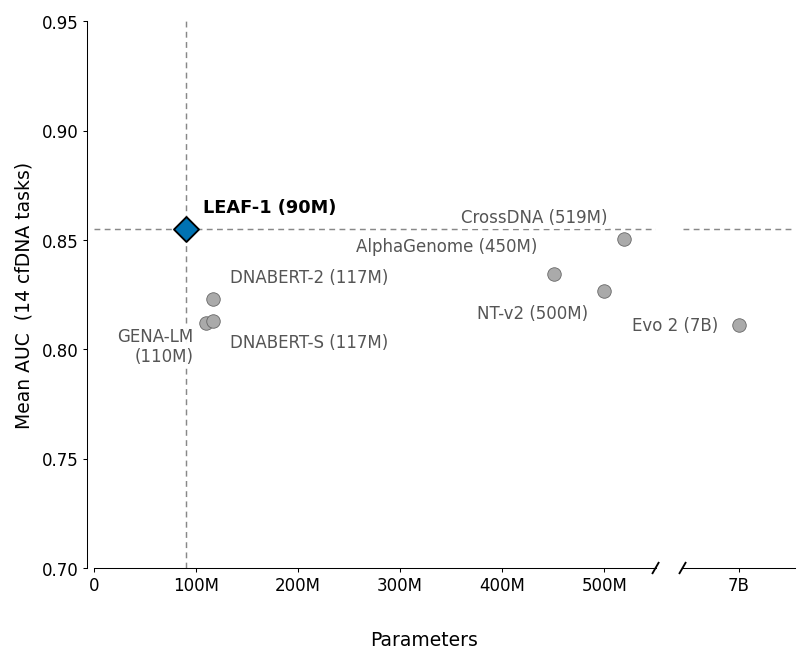

In [4]:
# ── Fig. 4d: mean AUC against parameter count ─────────────────────────────────
# Exact-source rcParams for this panel family.
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "DejaVu Sans", "Helvetica"],
    "font.size": 7, "axes.titlesize": 8, "axes.labelsize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 6,
    "axes.linewidth": 0.5, "xtick.major.width": 0.5, "ytick.major.width": 0.5,
    "xtick.major.size": 2, "ytick.major.size": 2, "xtick.major.pad": 2, "ytick.major.pad": 2,
    "figure.dpi": 150, "savefig.dpi": 600,
})
# (dx, dy, ha, va) in points. The six published models keep their published
# positions except NT-v2, which moves below its point to make room for the two
# added models that sit next to it.
LABEL_POS = {"LEAF-1": (8, 6, "left", "bottom"), "gena-lm": (-6, -2, "right", "top"),
             "dnabert2": (8, 6, "left", "bottom"), "dnabert-s": (8, -6, "left", "top"),
             "nt-v2": (-8, -6, "right", "top"), "evo2": (-10, 0, "right", "center"),
             "crossdna-519M-pm128": (-8, 6, "right", "bottom"),
             "alphagenome-npad-1bp": (-8, 9, "right", "bottom")}


def bca_ci_mean(vals, n_resamples=9999, seed=42):
    a = np.asarray(vals, dtype=float)
    r = sp_stats.bootstrap((a,), np.mean, n_resamples=n_resamples, confidence_level=0.95,
                           method="BCa", random_state=np.random.default_rng(seed))
    return float(np.mean(a)), float(r.confidence_interval.low), float(r.confidence_interval.high)


def fmtp(p):
    return f"{p / 1e9:.0f}B" if p >= 1e9 else f"{p / 1e6:.0f}M"


def label(m):
    return (f"{DISPLAY[m]}\n({fmtp(PARAMS[m])})" if m == "gena-lm"
            else f"{DISPLAY[m]} ({fmtp(PARAMS[m])})")


size_summary = {}
for m in MODELS:
    mu, lo, hi = bca_ci_mean(auc[m].values)
    size_summary[m] = {"mean_auc": mu, "ci_lo": lo, "ci_hi": hi, "params": PARAMS[m]}

fig, (ax_main, ax_far) = plt.subplots(1, 2, sharey=True, figsize=(5.5, 4.5),
                                      gridspec_kw={"width_ratios": [5, 1], "wspace": 0.08})


def plot_model(ax, m):
    s = size_summary[m]; x = s["params"]; y = s["mean_auc"]; leaf = m == "LEAF-1"
    ax.scatter(x, y, marker="D" if leaf else "o",
               color=OKABE_ITO["blue"] if leaf else "#AAAAAA", s=72 if leaf else 42,
               edgecolors="k" if leaf else "#666", linewidths=0.9 if leaf else 0.4,
               zorder=5 if leaf else 3)
    dx, dy, ha, va = LABEL_POS[m]
    ax.annotate(label(m), xy=(x, y), xytext=(dx, dy), textcoords="offset points",
                ha=ha, va=va, fontsize=8.5 if leaf else 8,
                fontweight="bold" if leaf else "normal", color="k" if leaf else "#555",
                bbox=dict(boxstyle="round,pad=0.15", fc=ax.get_facecolor(), ec="none", alpha=0.95),
                clip_on=False, zorder=6)


for m in [m for m in MODELS if PARAMS[m] < 1e9]:
    plot_model(ax_main, m)
for m in [m for m in MODELS if PARAMS[m] >= 1e9]:
    plot_model(ax_far, m)
# Dashed guides at LEAF-1's parameter count and mean AUC: the horizontal line runs
# across both panels so every model can be read as above/below LEAF-1 at a glance.
leaf_x, leaf_y = PARAMS["LEAF-1"], float(np.mean(auc["LEAF-1"].values))
guide = dict(color="#888888", lw=0.7, ls=(0, (4, 3)), zorder=1)
ax_main.axvline(leaf_x, **guide)
for a in (ax_main, ax_far):
    a.axhline(leaf_y, **guide)
ax_main.set_xlim(0, 550e6); ax_far.set_xlim(6.9e9, 7.1e9); ax_main.set_ylim(0.7, 0.95)
ax_main.set_xticks([0, 100e6, 200e6, 300e6, 400e6, 500e6])
ax_main.set_xticklabels(["0", "100M", "200M", "300M", "400M", "500M"])
ax_far.set_xticks([7e9]); ax_far.set_xticklabels(["7B"])
ax_main.set_ylabel("Mean AUC  (14 cfDNA tasks)", fontsize=9)
fig.text(0.52, 0.02, "Parameters", ha="center", va="bottom", fontsize=9)
ax_main.spines["right"].set_visible(False); ax_far.spines["left"].set_visible(False)
ax_far.tick_params(left=False, labelleft=False)
for a in (ax_main, ax_far):
    a.spines["top"].set_visible(False); a.tick_params(labelsize=8)
ax_main.spines["left"].set_position(("outward", 3))
fig.subplots_adjust(left=0.12, right=0.97, top=0.95, bottom=0.14)
# Break marks on the x-axis between the two panels.
fig.canvas.draw(); fig_w, fig_h = fig.get_size_inches(); tick_len = 0.08; angle = 60
dx = (tick_len * math.cos(math.radians(angle)) / 2) / fig_w
dy = (tick_len * math.sin(math.radians(angle)) / 2) / fig_h
for ax, cx in [(ax_main, 1.0), (ax_far, 0.0)]:
    p = fig.transFigure.inverted().transform(ax.transAxes.transform((cx, 0.0)))
    fig.add_artist(Line2D([p[0] - dx, p[0] + dx], [p[1] - dy, p[1] + dy],
                          transform=fig.transFigure, color="k", lw=0.9, clip_on=False))
savefig(fig, OUT, "cfdna_external_lm_model_size", data=pd.DataFrame([
    {"model": m, "display": DISPLAY[m], "params": size_summary[m]["params"],
     "mean_auc": size_summary[m]["mean_auc"], "ci_low": size_summary[m]["ci_lo"],
     "ci_high": size_summary[m]["ci_hi"]} for m in MODELS]))
plt.show()
